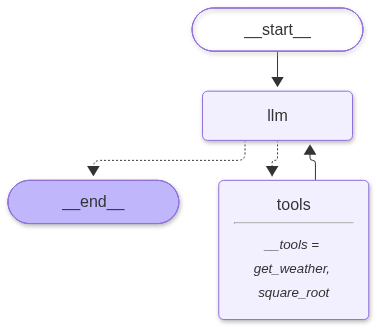

================================ Human Message =================================

杭州和上海天气如何？
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_00_sbAV6bLqGfvcKFE3Wrkh5498)
 Call ID: call_00_sbAV6bLqGfvcKFE3Wrkh5498
  Args:
    city: 杭州
  get_weather (call_01_NzIUVjTfzyqHhZiehBDS7776)
 Call ID: call_01_NzIUVjTfzyqHhZiehBDS7776
  Args:
    city: 上海
================================= Tool Message =================================
Name: get_weather

小雨 22度
================================= Tool Message =================================
Name: get_weather

多云 28度
================================== Ai Message ==================================

两地的天气情况如下：

- **杭州**：小雨，22°C
- **上海**：多云，28°C

杭州比上海低 6°C，而且正在下雨；去杭州的话记得带伞；上海相对更热、没有降雨，适合外出活动。


In [1]:
from dotenv import load_dotenv
from IPython.core.display import Image
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage
from langchain_core.tools import tool
from langgraph.constants import START
from langgraph.graph import MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition

load_dotenv(override=True)


# ====== Step 1: 准备工具 ======
@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    weather_data = {
        "北京": "晴天 25度",
        "上海": "多云 28度",
        "杭州": "小雨 22度",
    }
    return weather_data.get(city, f"未找到{city}的天气信息")


@tool
def square_root(x: float) -> str:
    """Calculate the square root of a number"""
    return x**0.5


# 组成工具数组
tools = [get_weather, square_root]
# 组成工具名和工具的映射，方便查找工具
tools_by_name = {t.name: t for t in tools}

# ====== Step 2: 准备模型，绑定工具 ======
model = init_chat_model("deepseek-flash", extra_body={"thinking": {"type": "disabled"}})

# 绑定工具到模型，与create_agent类似，将来LangChain会自动帮我们拼接tool信息发给模型
model_with_tools = model.bind_tools(tools)


def llm_node(state: MessagesState):
    """LLM节点：调用模型，可以选择调用工具"""
    response = model_with_tools.invoke(state["messages"])
    return {"messages": [response]}


# 4.添加Edge，连接Node，形成Graph
builder = StateGraph(MessagesState)
builder.add_node("tools", ToolNode(tools))
builder.add_node("llm", llm_node)

builder.add_edge(START, "llm")
builder.add_conditional_edges("llm", tools_condition)
builder.add_edge("tools", "llm")

graph = builder.compile()  # 3.4.编译成可执行图
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

# ===================4.调用graph======================
response = graph.invoke(
    {
        "messages": [
            # HumanMessage(content="一句话介绍你自己？"),
            HumanMessage(content="杭州和上海天气如何？"),
        ]
    }
)
for message in response["messages"]:
    message.pretty_print()